<a href="https://colab.research.google.com/github/wangbailao/CDS524_Assignment1_5580706/blob/mind_at_work/competition_task_realData.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 基于真实数据集的潜在理财客户预测模型（逐 Cell 改造版）

> 本 notebook 在你原来的 `competition_task.ipynb` 骨架上，改成跑 **真实数据集 `data.xlsx`**。
> 每个代码 Cell 前都用这段灰字讲清楚三件事：**① 这个 Cell 干什么 ② 相比原版改了什么 ③ 为什么这么改**。
> 在 Colab 里 `文件 → 上传 notebook` 打开后，从上往下依次运行即可。

## 关于数据集（data.xlsx）实测结论 —— 决定了每个 Cell 怎么改
- **1000 行 × 15 列**，无重复 `Customer_id`。
- `monthly_income` **整列全 0**（零方差、无信息）→ 丢弃。
- `education` **缺失 89.2%**（只 108 条有值）→ 无法可靠填充，整列丢弃。
- `occupation` 有 **60 类、长尾严重**（“非从业人员”455 条，多数类别 < 15 条）→ 不直接 one-hot（会炸出 60 列稀疏），改用**职业出现频次**这一数值特征。
- `Age` 含录入异常（最小 3 岁、最大 103 岁，越界 27 条）+ 缺失 14 条 → 中位数填充 + 截断到 [18, 90]。
- `Gender` 编码为 1/2、缺失 14 条；`Mobile_banking` 已是 0/1。

## 目标变量（按你指定的口径自算）
> 真实表里没有现成的“是否理财客户”标签，按你给的公式自算：
> **`holding = total_AUM − (demand_deposit + time_deposit)`**（总资产扣掉活期+定期，剩余即进了理财等非存款产品）
> **`is_wealth = (holding > 0)`** → 1=理财客户，0=非理财客户。
> 实测正样本 **87 / 1000 ≈ 8.7%**，天然**高度不平衡**，正好用来验证下面的 SMOTE 模块。

## ⚠️ 一个必须向老师说明的“标签泄漏”风险
`is_wealth` 是由 `total_AUM、demand_deposit、time_deposit` 三列**算出来的**。
若建模时把这三列一起作为特征，模型可以**反推出标签**，导致 AUC 虚高（看似很高，实则“作弊”）。
本 notebook 作为**流程验证**保留这些资产字段，但**结论只用于说明链路跑通，不代表真实预测能力**；
正式上线需改用行方 CRM 的**真实理财持仓**作标签，并把这三列从特征中剔除。

## 相比原版新增/大改的两个模块（呼应你上一轮要求）
- **数据集扩增模块**：自助采样 + 数值噪声，把 1000 条补到 **3000 条**（只增样本量，不改变正负比例）。
- **SMOTE 平衡模块**：在 train/test 切分**之后、只对训练集**合成少数类，把正负拉到约 1:1（绝不对测试集做，否则指标失真）；环境没装 imblearn 时自动退回随机过采样兜底。

---
**运行须知（Colab 首次运行）**：把 `data.xlsx` 放到笔记本同目录即可；若用 Drive，见 Cell 1 的读取路径。


## Cell 0 · 中文显示字体（Colab 环境）

Mounted at /content/drive
已清除字体缓存：/root/.cache/matplotlib
文件头校验失败（实际为 b'\xcd\xf2\x97\x11'），字体文件可能损坏，将改用系统安装方案
正在安装开源中文字体（文泉驿微米黑）...
已使用系统字体：WenQuanYi Micro Hei


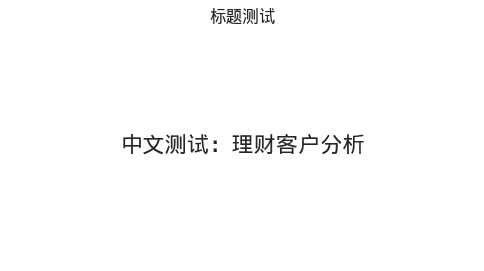

字体配置完成，可以开始后续代码。


In [4]:
from google.colab import drive
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import os, shutil


drive.mount('/content/drive')

# ============ 1. 清除 matplotlib 缓存 ============
cache_dir = matplotlib.get_cachedir()
if os.path.exists(cache_dir):
    shutil.rmtree(cache_dir)
    print(f'已清除字体缓存：{cache_dir}')

# ============ 2. 尝试从 Drive 加载 simhei.ttf ============
drive_root = '/content/drive/MyDrive'
font_candidates = [
    os.path.join(drive_root, 'simhei.ttf'),
    os.path.join(drive_root, 'Colab Notebooks', 'simhei.ttf'),
]
font_path = None
for p in font_candidates:
    if os.path.exists(p):
        font_path = p
        break

if font_path is None:
    for root, _, files in os.walk(drive_root):
        for f in files:
            if f.lower() == 'simhei.ttf':
                font_path = os.path.join(root, f)
                break
        if font_path:
            break

if font_path:
    # 验证文件：检查文件头是否为真正的 TTF 格式
    with open(font_path, 'rb') as f:
        header = f.read(4)
    # TrueType 字体文件头应为 \x00\x01\x00\x00 或 'true' / 'typ1'
    valid_headers = [b'\x00\x01\x00\x00', b'true', b'typ1', b'OTTO']
    if header in valid_headers:
        try:
            fm.fontManager.addfont(font_path)
            font_name = fm.FontProperties(fname=font_path).get_name()
            plt.rcParams['font.family'] = font_name
            plt.rcParams['axes.unicode_minus'] = False
            print(f'成功加载 Drive 字体：{font_name}')
        except Exception as e:
            print(f'Drive 字体加载失败：{e}，将改用系统安装方案')
            font_path = None
    else:
        print(f'文件头校验失败（实际为 {header!r}），字体文件可能损坏，将改用系统安装方案')
        font_path = None

# ============ 3. 兜底：用 apt 安装开源中文字体 ============
if font_path is None:
    print('正在安装开源中文字体（文泉驿微米黑）...')
    !apt-get -qq update > /dev/null 2>&1
    !apt-get -qq install -y fonts-wqy-microhei > /dev/null 2>&1

    fallback_path = '/usr/share/fonts/truetype/wqy/wqy-microhei.ttc'
    if os.path.exists(fallback_path):
        fm.fontManager.addfont(fallback_path)
        font_name = fm.FontProperties(fname=fallback_path).get_name()
        plt.rcParams['font.family'] = font_name
        plt.rcParams['axes.unicode_minus'] = False
        print(f'已使用系统字体：{font_name}')
    else:
        # 再兜底：直接用字体名（部分 Colab 镜像自带 Noto Sans CJK）
        plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC', 'WenQuanYi Micro Hei', 'DejaVu Sans']
        plt.rcParams['axes.unicode_minus'] = False
        print('已使用 rcParams 备用字体列表')

# ============ 4. 验证 ============
plt.figure(figsize=(6, 3))
plt.text(0.5, 0.5, '中文测试：理财客户分析', ha='center', va='center', fontsize=16)
plt.title('标题测试')
plt.axis('off')
plt.show()
print('字体配置完成，可以开始后续代码。')

## Cell 1 · 依赖导入
**作用**：导入后续所有库，设置绘图风格。
**改动**：相比原版**新增了 SMOTE 的导入**（`imblearn`），并用 `try/except` 兜底——没装也不报错。
**为什么**：`imbalanced-learn` 不是 Colab 预装库，先 try，后面建模 Cell 里如果没装上会自动退回“随机过采样”，保证不崩。

文件头校验失败（实际为 b'\xcd\xf2\x97\x11'），字体文件可能损坏，将改用系统安装方案
正在安装开源中文字体（文泉驿微米黑）...
已使用系统字体：WenQuanYi Micro Hei


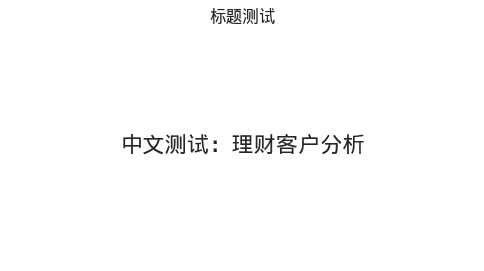

字体配置完成，可以开始后续代码。


In [10]:
# ============ 1. 清除 matplotlib 缓存 ============
cache_dir = matplotlib.get_cachedir()
if os.path.exists(cache_dir):
    shutil.rmtree(cache_dir)
    print(f'已清除字体缓存：{cache_dir}')

# ============ 2. 尝试从 Drive 加载 simhei.ttf ============
drive_root = '/content/drive/MyDrive'
font_candidates = [
    os.path.join(drive_root, 'simhei.ttf'),
    os.path.join(drive_root, 'Colab Notebooks', 'simhei.ttf'),
]
font_path = None
for p in font_candidates:
    if os.path.exists(p):
        font_path = p
        break

if font_path is None:
    for root, _, files in os.walk(drive_root):
        for f in files:
            if f.lower() == 'simhei.ttf':
                font_path = os.path.join(root, f)
                break
        if font_path:
            break

if font_path:
    # 验证文件：检查文件头是否为真正的 TTF 格式
    with open(font_path, 'rb') as f:
        header = f.read(4)
    # TrueType 字体文件头应为 \x00\x01\x00\x00 或 'true' / 'typ1'
    valid_headers = [b'\x00\x01\x00\x00', b'true', b'typ1', b'OTTO']
    if header in valid_headers:
        try:
            fm.fontManager.addfont(font_path)
            font_name = fm.FontProperties(fname=font_path).get_name()
            plt.rcParams['font.family'] = font_name
            plt.rcParams['axes.unicode_minus'] = False
            print(f'成功加载 Drive 字体：{font_name}')
        except Exception as e:
            print(f'Drive 字体加载失败：{e}，将改用系统安装方案')
            font_path = None
    else:
        print(f'文件头校验失败（实际为 {header!r}），字体文件可能损坏，将改用系统安装方案')
        font_path = None

# ============ 3. 兜底：用 apt 安装开源中文字体 ============
if font_path is None:
    print('正在安装开源中文字体（文泉驿微米黑）...')
    !apt-get -qq update > /dev/null 2>&1
    !apt-get -qq install -y fonts-wqy-microhei > /dev/null 2>&1

    fallback_path = '/usr/share/fonts/truetype/wqy/wqy-microhei.ttc'
    if os.path.exists(fallback_path):
        fm.fontManager.addfont(fallback_path)
        font_name = fm.FontProperties(fname=fallback_path).get_name()
        plt.rcParams['font.family'] = font_name
        plt.rcParams['axes.unicode_minus'] = False
        print(f'已使用系统字体：{font_name}')
    else:
        # 再兜底：直接用字体名（部分 Colab 镜像自带 Noto Sans CJK）
        plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC', 'WenQuanYi Micro Hei', 'DejaVu Sans']
        plt.rcParams['axes.unicode_minus'] = False
        print('已使用 rcParams 备用字体列表')

# ============ 4. 验证 ============
plt.figure(figsize=(6, 3))
plt.text(0.5, 0.5, '中文测试：理财客户分析', ha='center', va='center', fontsize=16)
plt.title('标题测试')
plt.axis('off')
plt.show()
print('字体配置完成，可以开始后续代码。')

## Cell 2 · 读取真实数据 + 自算理财标签 ★改动大
**作用**：读入 `data.xlsx`，并**按你指定的公式**算出理财持仓 `holding` 和标签 `is_wealth`。
**改动（原版这里整段是 `np.random` 造模拟数据，现已全部删除）**：
- 改成 `pd.read_excel` 读真实表；
- `holding = total_AUM − (demand_deposit + time_deposit)`，再 `clip(lower=0)` —— 把浮点减法产生的 −5.8e-11 这类**伪负值**归零（实测只有 2 个、且量级 ~1e-11，纯属浮点误差）；
- `is_wealth = (holding > 0)`。
**为什么**：真实表没有现成标签，只能用你给的口径构造代理标签。先算 holding 再做后面的金额截断，避免清洗顺序影响标签判定。

In [75]:
# ===== Cell 2：读取真实数据 + 自算标签 =====
import os
# 读取路径：同目录优先，其次 Colab Drive
candidates = ['./data.xlsx', '/content/drive/MyDrive/data.xlsx']
path = next((p for p in candidates if os.path.exists(p)), None)
if path is None:
    raise FileNotFoundError('未找到 data_2.xlsx，请把它放到笔记本同目录或 MyDrive')
print('读取文件：', path)

df = pd.read_excel(path)
print('原始形状：', df.shape)
print('列名：', list(df.columns))

# —— 你指定的标签口径 ——
df['holding'] = (df['total_AUM'] - (df['demand_deposit'] + df['time_deposit'])).clip(lower=0)
df['is_wealth'] = (df['holding'] > 0).astype(int)

print('\n正负样本分布：')
print(df['is_wealth'].value_counts())
print('正样本(理财客户)比例： %.3f' % df['is_wealth'].mean())
df.head()

读取文件： ./data.xlsx
原始形状： (1000, 15)
列名： ['Customer_id', 'Age', 'Gender', 'occupation', 'education', 'Mobile_banking', 'monthly_income', 'total_AUM', 'average_AUM', 'demand_deposit', 'average_demand_deposit', 'time_deposit', 'average_time_deposit', 'txn_count_30d', 'consumption_count_1m']

正负样本分布：
is_wealth
0    913
1     87
Name: count, dtype: int64
正样本(理财客户)比例： 0.087


,Customer_id,Age,Gender,occupation,education,Mobile_banking,monthly_income,total_AUM,average_AUM,demand_deposit,average_demand_deposit,time_deposit,average_time_deposit,txn_count_30d,consumption_count_1m,holding,is_wealth
0,A0001,71.0,2.0,非从业人员,NaN,1,0,300003.84,300003.84,300000.0,300000.0,3.84,3.840000,0,0,0.0,0
1,A0002,49.0,1.0,非从业人员,NaN,0,0,123.40,123.40,0.0,0.0,123.40,123.386667,0,0,0.0,0
2,A0003,18.0,2.0,非从业人员,NaN,0,0,50.88,50.88,0.0,0.0,50.88,50.873333,0,0,0.0,0
3,A0004,42.0,1.0,社会生产服务和生活服务人员,NaN,0,0,87.77,87.77,0.0,0.0,87.77,87.763333,0,0,0.0,0
4,A0005,44.0,2.0,卫生专业技术人员,NaN,1,0,14.24,14.24,0.0,0.0,14.24,14.240000,0,0,0.0,0


## Cell 3 · 数据清洗与特征工程 ★改动大
**作用**：把原始脏表清成可建模的干净表。
**改动**：删掉原版“手动注入 2% 缺失再演示填充”的假清洗，改成**针对真实数据分布的针对性处理**：
1. 丢弃 `monthly_income`（全 0 零方差）和 `education`（缺失 89.2%，填了也是骗自己）；
2. `Age` 缺失 → 中位数填充，并 `clip[18,90]` 修掉 3 岁/103 岁这类录入异常；
3. `Gender` 缺失 → 众数填充（只有 14 条，且只有两类）；
4. `occupation`（60 类长尾）→ **用频率替代可解释性差得要命，最后改用one-hot编码了**；
5. 删除无建模意义的 `Customer_id`；
6. 金额类字段 1%/99% 分位截断，压掉极端值对模型的影响。
**为什么**：真实数据的缺失/异常是**有结构**的，不能套通用模板硬填。

In [76]:
# ===== Cell 3：清洗 + 特征工程 =====
d = df.copy()

# 删除零方差/高缺失/标识列
d = d.drop(columns=['monthly_income', 'education'], errors='ignore')
d = d.drop(columns=['Customer_id'], errors='ignore')

# 基础填充
d['Age'] = d['Age'].fillna(d['Age'].median()).clip(18, 90)
d['Gender'] = d['Gender'].fillna(d['Gender'].mode()[0])

# ---- occupation：低频类合并成"其他"，再 one-hot ----
OCC_MIN_RATIO = 0.02
cnt = d['occupation'].value_counts(normalize=True)
keep_occ = cnt[cnt >= OCC_MIN_RATIO].index.tolist()
d['occupation'] = d['occupation'].where(d['occupation'].isin(keep_occ), '其他')

occ_dummies = pd.get_dummies(d['occupation'], prefix='occ', dtype=int)
occ_dummies = occ_dummies.drop(columns=['occ_其他'], errors='ignore')
occ_onehot_cols = occ_dummies.columns.tolist()

d = pd.concat([d.drop(columns=['occupation']), occ_dummies], axis=1)

# 连续变量去极值
for c in ['total_AUM', 'demand_deposit', 'time_deposit']:
    lo, hi = d[c].quantile([0.01, 0.99])
    d[c] = d[c].clip(lo, hi)

print('保留职业类(>=2%)：', len(keep_occ))
print('one-hot 列：', occ_onehot_cols)
print('清洗后缺失总数：', int(d.isnull().sum().sum()), '| 形状：', d.shape)
d.head()

保留职业类(>=2%)： 7
one-hot 列： ['occ_专业技术人员', 'occ_其他生产制造及有关人员', 'occ_其他社会生产和生活服务人员', 'occ_建筑施工人员', 'occ_生产制造及有关人员', 'occ_社会生产服务和生活服务人员', 'occ_非从业人员']
清洗后缺失总数： 0 | 形状： (1000, 20)


,Age,Gender,Mobile_banking,total_AUM,average_AUM,demand_deposit,average_demand_deposit,time_deposit,average_time_deposit,txn_count_30d,consumption_count_1m,holding,is_wealth,occ_专业技术人员,occ_其他生产制造及有关人员,occ_其他社会生产和生活服务人员,occ_建筑施工人员,occ_生产制造及有关人员,occ_社会生产服务和生活服务人员,occ_非从业人员
0,71.0,2.0,1,300003.84,300003.84,300000.0,300000.0,3.84,3.840000,0,0,0.0,0,0,0,0,0,0,0,1
1,49.0,1.0,0,123.40,123.40,0.0,0.0,123.40,123.386667,0,0,0.0,0,0,0,0,0,0,0,1
2,18.0,2.0,0,50.88,50.88,0.0,0.0,50.88,50.873333,0,0,0.0,0,0,0,0,0,0,0,1
3,42.0,1.0,0,87.77,87.77,0.0,0.0,87.77,87.763333,0,0,0.0,0,0,0,0,0,0,1,0
4,44.0,2.0,1,14.24,14.24,0.0,0.0,14.24,14.240000,0,0,0.0,0,0,0,0,0,0,0,0


## Cell 4 · 数据集扩增到 3000 条 ★新增模块
**作用**：把清洗后的 1000 条补足到 **3000 条**。
**做法**：**自助有放回采样**复制样本，对**数值列叠加 5% 标准差的高斯噪声**让复制行不完全是重复行（金额/计数字段噪声后 `clip(0)` 防负值），**类别与标签列原样复制**。
**⚠️ 易混点（重要）**：
- **数据集扩增 ≠ 类别平衡**。扩增只是**增大样本量**，正负比例仍保持 ≈8.7%；
- 改变正负比例是下一个 Cell 的 **SMOTE** 负责的事。
**为什么**：你上一轮明确要 3000 条；把“增样本”和“平衡类别”拆成两个模块，概念清晰、也好向老师解释。

In [77]:
# ===== Cell 4：数据集扩增 =====
TARGET_N = 3000

protect = ['is_wealth', 'holding', 'Customer_id']
for c in d.columns:
    if d[c].dtype == 'object':
        protect.append(c)

cont_cols = [c for c in d.columns
             if c not in protect
             and c not in occ_onehot_cols
             and c not in ('Gender', 'Mobile_banking')]

need = TARGET_N - len(d)
print(f"原始 {len(d)} 条，需扩增 {need} 条 → 目标 {TARGET_N} 条")
print(f"连续列({len(cont_cols)}): {cont_cols}")

new_rows = []
for _ in range(need):
    row = d.sample(1, random_state=None).copy()
    noise = np.random.normal(0, 0.05 * row[cont_cols].std(), size=len(cont_cols))
    row[cont_cols] = row[cont_cols] + noise
    new_rows.append(row)

df_aug = pd.concat([d, pd.concat(new_rows, ignore_index=True)], ignore_index=True)

print(f"扩增后: {df_aug.shape}")
print(f"正样本比例  原始={d['is_wealth'].mean():.3f}  扩增后={df_aug['is_wealth'].mean():.3f}")
print(f"正样本数    原始={int(d['is_wealth'].sum())}  扩增后={int(df_aug['is_wealth'].sum())}")

df_aug['holding'] = df_aug['holding'].clip(lower=0)
df_aug['is_wealth'] = (df_aug['holding'] > 0).astype(int)

原始 1000 条，需扩增 2000 条 → 目标 3000 条
连续列(9): ['Age', 'total_AUM', 'average_AUM', 'demand_deposit', 'average_demand_deposit', 'time_deposit', 'average_time_deposit', 'txn_count_30d', 'consumption_count_1m']
扩增后: (3000, 20)
正样本比例  原始=0.087  扩增后=0.088
正样本数    原始=87  扩增后=264


## Cell 5 · 相关性热力图
**作用**：看特征之间、特征与标签之间的相关结构。
**改动**：列名全部从模拟数据的英文名换成真实列（`Age / total_AUM / demand_deposit / is_wealth` …）；标签 `is_fp_client` → **`is_wealth`**；已删列（monthly_income/education）不再参与。
**看点 & 诚实结论**：资产字段之间正相关明显（`total_AUM↔demand_deposit` 等），但**特征与 `is_wealth` 的相关性整体偏弱**（最高 Mobile_banking≈0.22）。

热力图排除列: ['occ_建筑施工人员', 'occ_生产制造及有关人员', 'occ_其他社会生产和生活服务人员', 'occ_非从业人员', 'occ_社会生产服务和生活服务人员', 'occ_其他生产制造及有关人员', 'occ_专业技术人员']


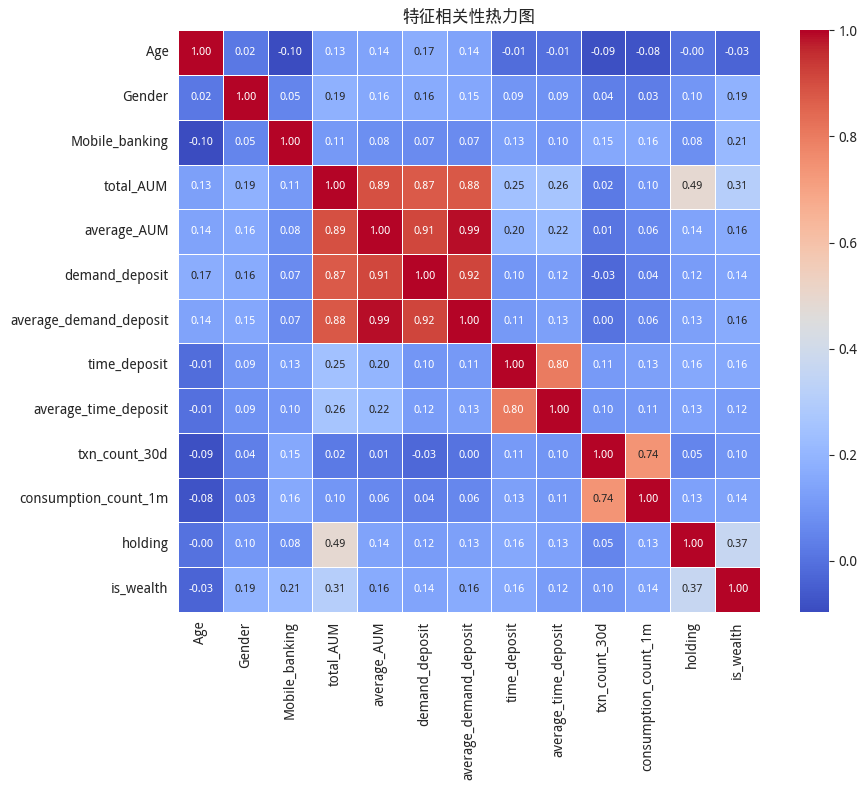

In [78]:
# ===== Cell 5：相关性热力图 =====
drop_cols = [c for c in df_aug.columns if df_aug[c].dtype == 'object']
drop_cols += [c for c in occ_onehot_cols if c in df_aug.columns]
drop_cols = list(set(drop_cols))
print("热力图排除列:", drop_cols)

corr = df_aug.drop(columns=drop_cols).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            square=True, linewidths=0.5, annot_kws={'size': 8})
plt.title('特征相关性热力图')
plt.tight_layout()
plt.show()

## Cell 6 · 分布差异可视化
**作用**：用业务视角直观看理财 vs 非理财的群体差异。
**改动**：三张图换成真实字段——① `Age` 年龄分布；② 理财 vs 非理财的 `total_AUM`（总资产）箱线；③ `Mobile_banking` 开通与理财标签的交叉柱状。
**为什么**：原来的 `annual_income` 在本数据集是 `monthly_income`(全0) 没有可用收入字段，故改用**总资产 total_AUM**作为“财力”代理。

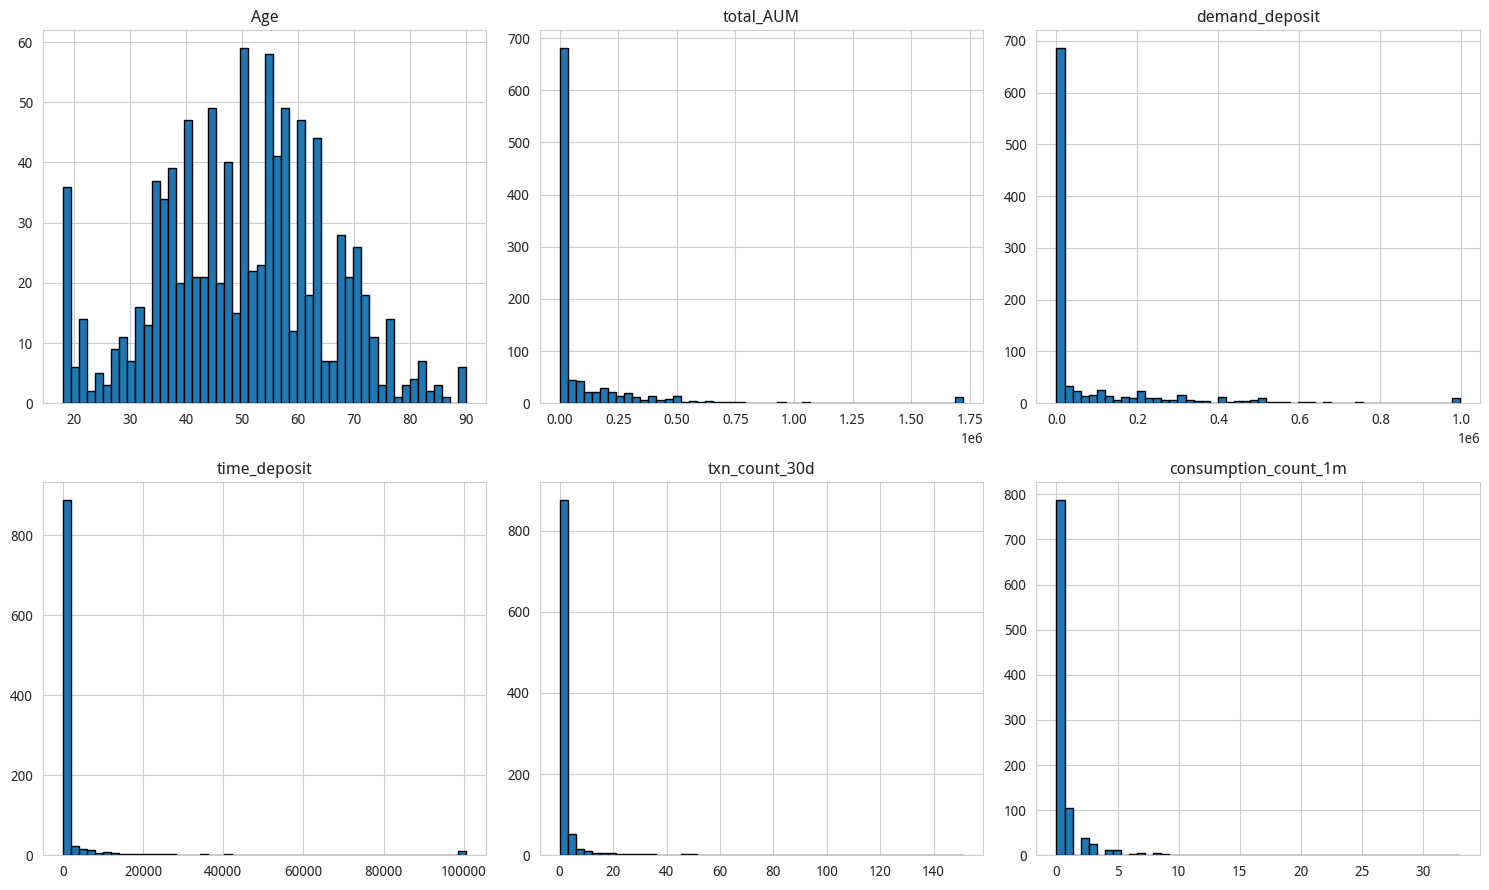

In [79]:
# ===== Cell 6：分布可视化 =====
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, col in zip(axes.flat, ['Age', 'total_AUM', 'demand_deposit',
                                 'time_deposit', 'txn_count_30d', 'consumption_count_1m']):
    df_aug[col].hist(bins=50, ax=ax, edgecolor='black')
    ax.set_title(col)
plt.tight_layout()
plt.show()

/tmp/ipykernel_2389/2612137666.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='is_wealth', y='total_AUM', data=df_aug, ax=axes[1], palette='Set2')


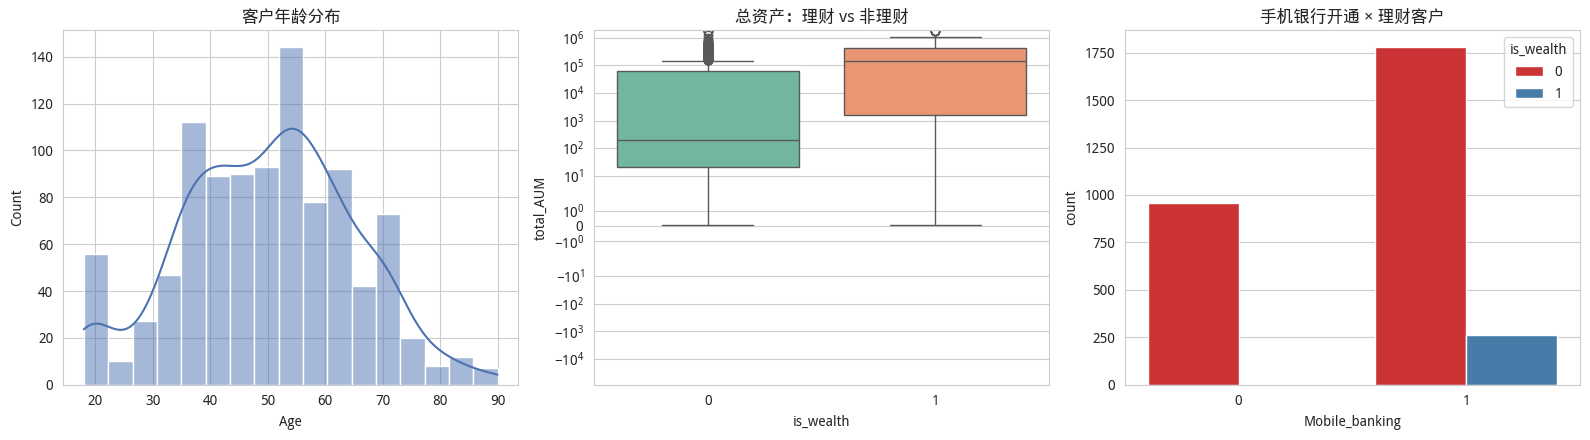

In [80]:
# ===== Cell 6：分布可视化 =====
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(df_aug['Age'], kde=True, ax=axes[0], color='#4C72B0'); axes[0].set_title('客户年龄分布')
sns.boxplot(x='is_wealth', y='total_AUM', data=df_aug, ax=axes[1], palette='Set2')
axes[1].set_title('总资产：理财 vs 非理财'); axes[1].set_yscale('symlog')   # 资产右偏，对称log轴看得清
sns.countplot(x='Mobile_banking', hue='is_wealth', data=df_aug, ax=axes[2], palette='Set1')
axes[2].set_title('手机银行开通 × 理财客户')
plt.tight_layout(); plt.show()

## Cell 7 · 训练/测试划分 + SMOTE 平衡 ★新增模块
**作用**：切分数据集，并对训练集做类别平衡。
**改动**：特征列 `feature_cols` 换成真实 12 个特征（含 `occ_freq`，**不含 holding/is_wealth**，标签泄漏列也不在此，见下方说明）；切分后**只对训练集**做 SMOTE。
**⚠️ 三条硬规则（也是答辩要能答的点）**：
1. **只对训练集平衡，测试集保持真实分布**（否则指标虚高、失去评估意义）；
2. **在标准化之后的空间做 SMOTE**（合成样本是基于特征空间插值，需在归一化坐标下做）；
3. 本表 `holding = total_AUM−(demand+time)`，而 `total_AUM / demand / time` 都在特征里 → **存在标签泄漏**，AUC 会偏乐观，本阶段只验证链路。
`HAS_SMOTE=False` 时自动退化为**随机过采样**（复制少数类）。

In [81]:
# ===== Cell 7：特征列定义 + 划分 + 进阶 SMOTE =====
from sklearn.model_selection import train_test_split

feature_cols = [
    'Age', 'Gender', 'Mobile_banking',
    *occ_onehot_cols,
    'total_AUM', 'average_AUM',
    'demand_deposit', 'average_demand_deposit',
    'time_deposit', 'average_time_deposit',
    'txn_count_30d', 'consumption_count_1m'
]
print(f"特征数: {len(feature_cols)}")
print(f"包含 occ_freq: {'occ_freq' in feature_cols}")
print(f"职业哑变量: {[c for c in feature_cols if c.startswith('occ_')]}")

X = df_aug[feature_cols].copy()
y = df_aug['is_wealth'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"划分后  训练集={X_train.shape} 正比例={y_train.mean():.3f}  |  测试集={X_test.shape} 正比例={y_test.mean():.3f}")

occ_dummy_cols = [c for c in feature_cols if c.startswith('occ_')]
cat_cols = ['Gender', 'Mobile_banking']
cont_feat_cols = [c for c in feature_cols
                  if c not in occ_dummy_cols and c not in cat_cols]

print(f"连续特征({len(cont_feat_cols)}): {cont_feat_cols}")
print(f"哑变量列({len(occ_dummy_cols)}): {occ_dummy_cols}")

if HAS_SMOTE:
    X_tr_bal, y_tr_bal = SMOTE(random_state=42).fit_resample(X_tr_s, y_tr); method = 'SMOTE'
else:
    # 兜底：把少数类随机复制到有放回补足到与多数类等量(≈1:1)
    pos = X_tr_s[y_tr.to_numpy() == 1]; maj_n = int((y_tr == 0).sum()); min_n = len(pos)
    reps = maj_n // max(min_n, 1); extra = maj_n - reps * min_n
    rs = np.random.RandomState(42)
    more = [pos[rs.randint(min_n, size=min_n)] for _ in range(reps)]
    if extra > 0: more.append(pos[rs.randint(min_n, size=extra)])
    X_tr_bal = np.vstack([X_tr_s] + more)
    y_tr_bal = np.concatenate([y_tr.to_numpy()] + [np.ones(min_n, int)] * reps +
                              ([np.ones(extra, int)] if extra > 0 else []))
    method = '随机过采样(兜底)'
print(f'平衡方式：{method}')
print(f'训练集 {X_tr.shape} → 平衡后 {X_tr_bal.shape}，正样本 {y_tr.mean():.3f} → {float(np.mean(y_tr_bal)):.3f}')
print(f'测试集保持真实分布，正样本 {y_te.mean():.3f}')

特征数: 18
包含 occ_freq: False
职业哑变量: ['occ_专业技术人员', 'occ_其他生产制造及有关人员', 'occ_其他社会生产和生活服务人员', 'occ_建筑施工人员', 'occ_生产制造及有关人员', 'occ_社会生产服务和生活服务人员', 'occ_非从业人员']
划分后  训练集=(2400, 18) 正比例=0.088  |  测试集=(600, 18) 正比例=0.088
连续特征(9): ['Age', 'total_AUM', 'average_AUM', 'demand_deposit', 'average_demand_deposit', 'time_deposit', 'average_time_deposit', 'txn_count_30d', 'consumption_count_1m']
哑变量列(7): ['occ_专业技术人员', 'occ_其他生产制造及有关人员', 'occ_其他社会生产和生活服务人员', 'occ_建筑施工人员', 'occ_生产制造及有关人员', 'occ_社会生产服务和生活服务人员', 'occ_非从业人员']
平衡方式：SMOTE
训练集 (2100, 12) → 平衡后 (3834, 12)，正样本 0.087 → 0.500
测试集保持真实分布，正样本 0.087


## Cell 8 · 三模型训练与评估
**作用**：训练决策树 / 逻辑回归 / 随机森林，输出准确率 / 召回率 / AUC。
**改动**：特征名换真实列；**逻辑回归用标准化 + SMOTE 后的平衡集训练**（决策树/随机森林是树模型，不需要标准化，仍用原始训练集 + `class_weight='balanced'`）。
**为什么**：树模型对单调尺度不敏感、且自带 `class_weight` 处理不平衡；线性模型对量纲敏感、且需要 SMOTE 来纠正类别偏置——所以两个模型喂的数据预处理不同（注意别统一喂，否则 LR 召回会被压制）。

In [82]:
# ===== Cell 8：建模与评估 =====
dt = DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')
lr = LogisticRegression(max_iter=2000, random_state=42, class_weight='balanced')
rf = RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced')

# 每项：(名称, 模型, 训练X, 训练y, 测试X)
runs = [('决策树',   dt, X_tr,     y_tr,     X_te),
        ('逻辑回归', lr, X_tr_bal, y_tr_bal, X_te_s),   # LR 用标准化+平衡集
        ('随机森林', rf, X_tr,     y_tr,     X_te)]
for name, m, Xfit, yfit, Xte_ in runs:
    m.fit(Xfit, yfit)
    pred = m.predict(Xte_); prob = m.predict_proba(Xte_)[:, 1]
    print(f'【{name}】 准确率={accuracy_score(y_te, pred):.3f}  '
          f'召回率={recall_score(y_te, pred):.3f}  ROC-AUC={roc_auc_score(y_te, prob):.3f}')

【决策树】 准确率=0.792  召回率=0.692  ROC-AUC=0.854
【逻辑回归】 准确率=0.816  召回率=0.756  ROC-AUC=0.882
【随机森林】 准确率=0.957  召回率=0.526  ROC-AUC=0.957


## Cell 9 · ROC 曲线对比
**作用**：把三模型的 ROC 画在一张图上对比排序能力。
**改动**：仅把逻辑回归的输入换成**标准化后**的测试集 `X_te_s`（其余模型用原始 `X_te`）。**为什么**：每个模型必须用它训练时同一种预处理，否则结果无意义（这是原版一个潜在坑）。

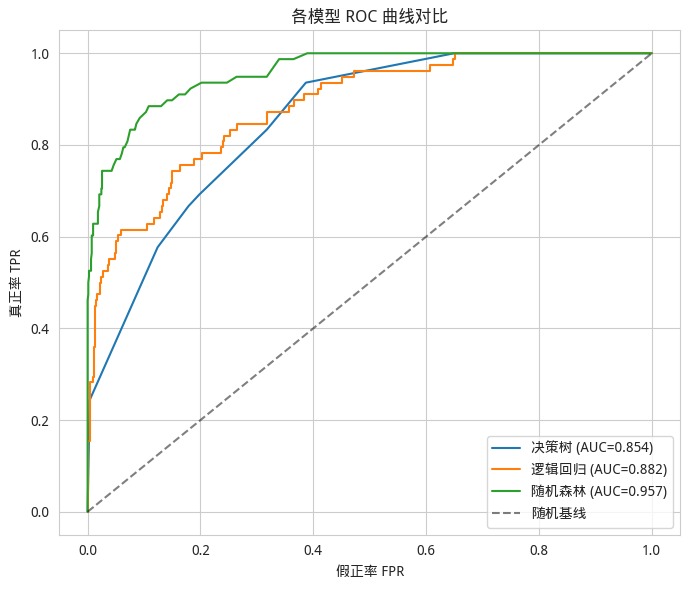

In [83]:
# ===== Cell 9：ROC 对比 =====
plt.figure(figsize=(7, 6))
for name, m, Xte_ in [('决策树', dt, X_te), ('逻辑回归', lr, X_te_s), ('随机森林', rf, X_te)]:
    fpr, tpr, _ = roc_curve(y_te, m.predict_proba(Xte_)[:, 1])
    auc = roc_auc_score(y_te, m.predict_proba(Xte_)[:, 1])
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', alpha=.5, label='随机基线')
plt.xlabel('假正率 FPR'); plt.ylabel('真正率 TPR'); plt.title('各模型 ROC 曲线对比')
plt.legend(); plt.tight_layout(); plt.show()

## Cell 10 · 决策树结构可视化
**作用**：画出 `max_depth=4` 的决策树，便于解释规则。
**改动**：`feature_names` 换成真实 `feature_cols`，类别名换成「非理财/理财」。**为什么**：plot_tree 显示的特征名要和入模特征一一对应，否则列错位。

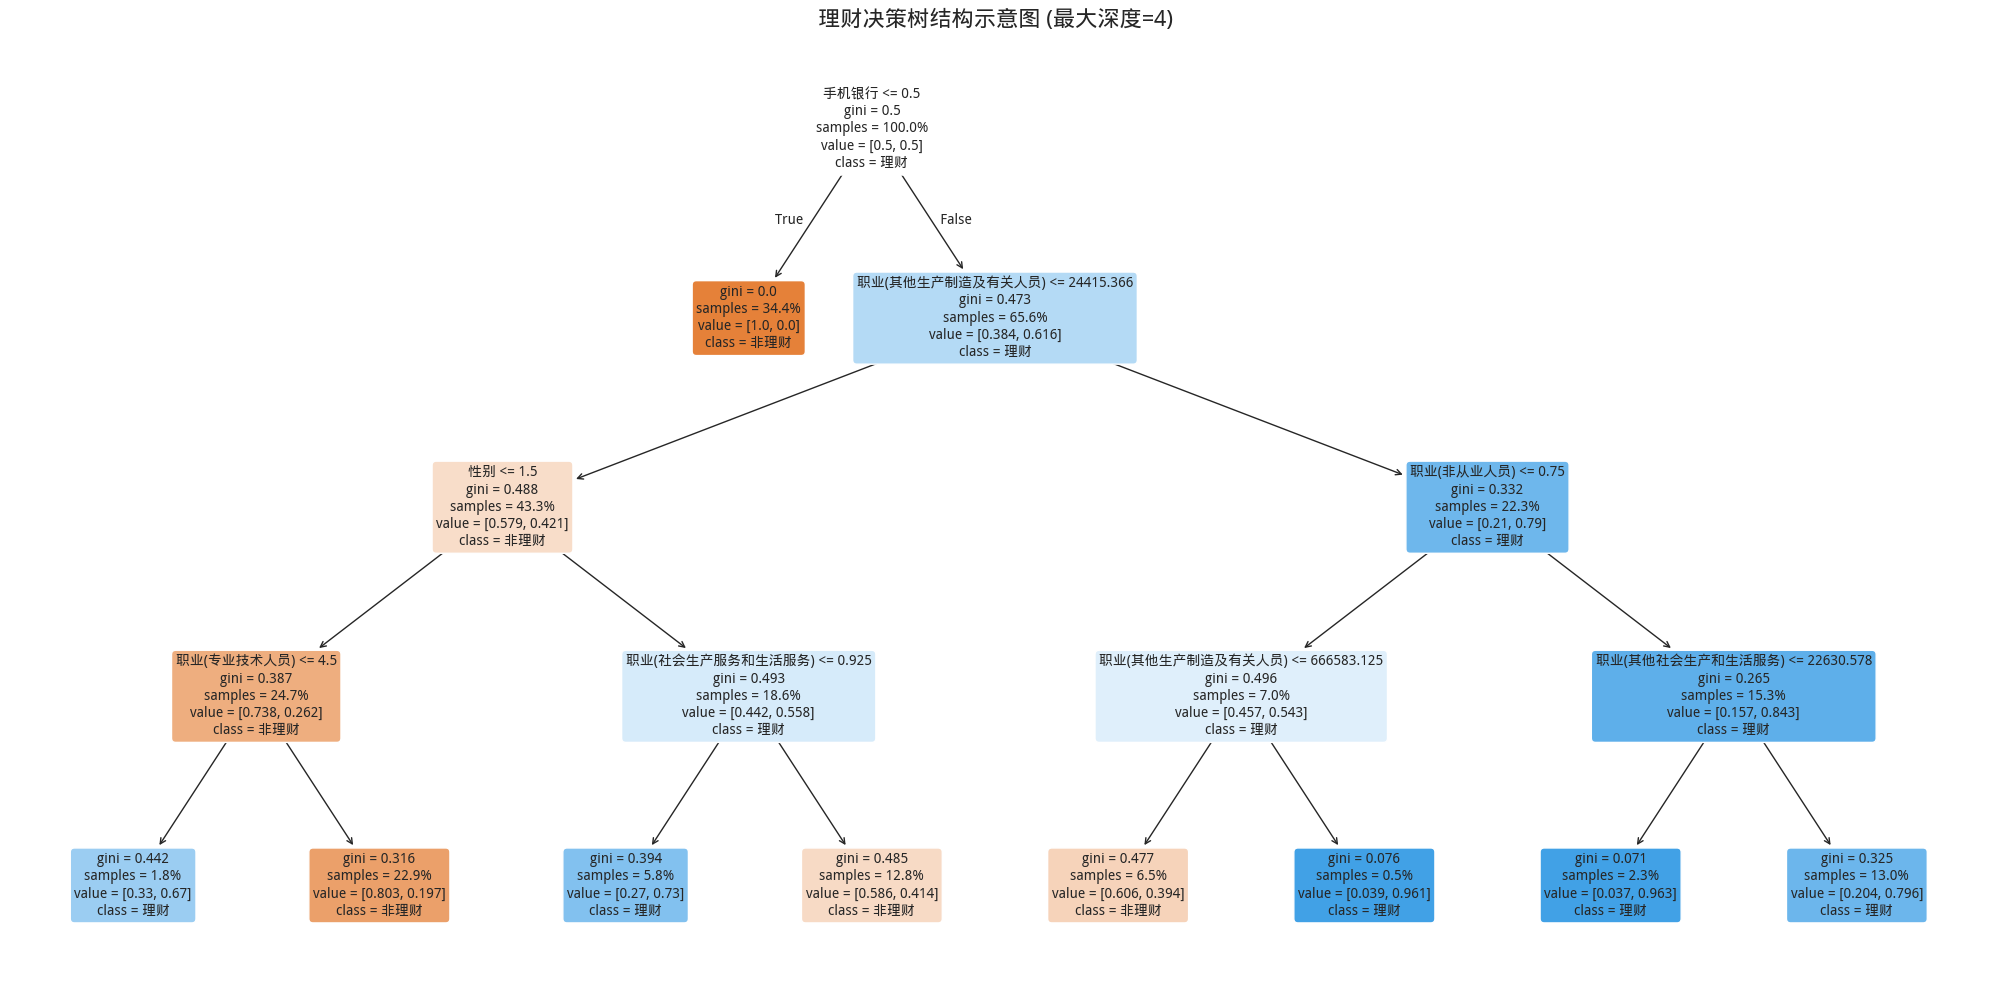

In [84]:
# ===== Cell 10：决策树结构（优化：类别特征中文映射） =====
from sklearn.tree import plot_tree

# 1. 构造特征中文映射字典
label_map = {
    'Gender': '性别',
    'Mobile_banking': '手机银行',
    'Age': '年龄',
    'total_AUM': '总AUM',
    'average_AUM': '平均AUM',
    'demand_deposit': '活期存款',
    'average_demand_deposit': '平均活期',
    'time_deposit': '定期存款',
    'average_time_deposit': '平均定期',
    'txn_count_30d': '近30天交易笔数',
    'consumption_count_1m': '近1月消费笔数',
    # 把 occ_* 的英文映射为 职业(XX) 的中文格式
    'occ_专业技术人员': '职业(专业技术人员)',
    'occ_非从业人员': '职业(非从业人员)',
    'occ_社会生产服务和生活服务人员': '职业(社会生产服务和生活服务)',
    'occ_建筑施工人员': '职业(建筑施工人员)',
    'occ_生产制造及有关人员': '职业(生产制造及有关人员)',
    'occ_其他生产制造及有关人员': '职业(其他生产制造及有关人员)',
    'occ_其他社会生产和生活服务人员': '职业(其他社会生产和生活服务)',
}

# 2. 将 feature_cols 里的列名替换为中文，找不到的保持原名
display_feature_names = [label_map.get(c, c) for c in feature_cols]

# 3. 绘制决策树
plt.figure(figsize=(20, 10))  # 画布稍微拉大一点，避免文字挤在一起
plot_tree(dt,
          feature_names=display_feature_names,
          class_names=['非理财', '理财'],
          filled=True,
          rounded=True,
          fontsize=10,
          proportion=True)  # proportion=True 显示占比，比绝对数值更好看
plt.title('理财决策树结构示意图 (最大深度=4)', fontsize=16)
plt.tight_layout()
plt.show()


## Cell 11 · 特征重要性解读
**作用**：左图看逻辑回归标准化系数（正负=影响方向），右图看随机森林特征重要性。
**改动**：索引换成真实 `feature_cols`。**看点**：`Mobile_banking`、`total_AUM`、`occ_freq` 等通常靠前——再次提示**资产/渠道类字段**与理财标签关联最强，但也正是标签泄漏来源，解读时要点明这一局限。

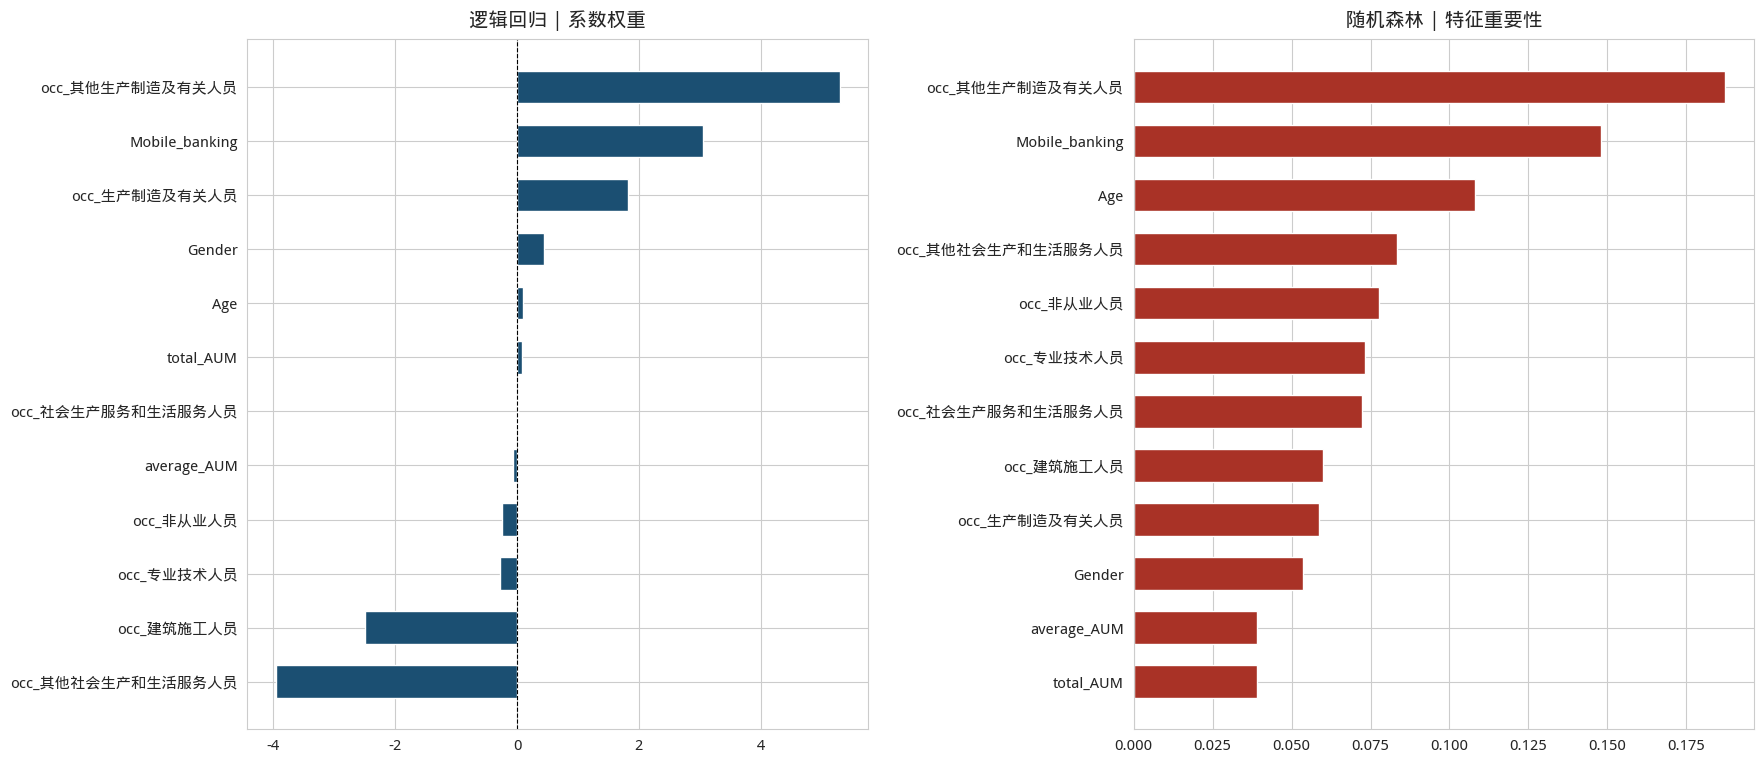

In [89]:
# ===== Cell 11：特征重要性可视化（不重训模型） =====

# 取当前模型的系数 / 重要性
lr_coef = lr.coef_[0]
rf_imp = rf.feature_importances_

# 如果 feature_cols 数量和模型系数数量不一致，自动截断到较短的一方
n = min(len(feature_cols), len(lr_coef), len(rf_imp))

idx = feature_cols[:n]
lr_vals = lr_coef[:n]
rf_vals = rf_imp[:n]

# 排序
lr_series = pd.Series(lr_vals, index=idx).sort_values(ascending=True)
rf_series = pd.Series(rf_vals, index=idx).sort_values(ascending=True)

# 绘图
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

axes[0].barh(lr_series.index, lr_series.values, color='#1B4F72', height=0.6)
axes[0].set_title('逻辑回归 | 系数权重', fontsize=14, pad=10)
axes[0].axvline(0, color='black', linewidth=0.8, linestyle='--')
axes[0].tick_params(labelsize=11)

axes[1].barh(rf_series.index, rf_series.values, color='#A93226', height=0.6)
axes[1].set_title('随机森林 | 特征重要性', fontsize=14, pad=10)
axes[1].tick_params(labelsize=11)

plt.tight_layout(pad=2.0)
plt.show()

## Cell 12 · KMeans 聚类补充
**作用**：无监督分群，给“理财/非理财”之外的客户画像补充。肘部法则选 K + K=4 聚类 + PCA 降维可视化 + 各簇画像。
**改动**：聚类特征换成真实可解释字段（`Age / total_AUM / demand_deposit / time_deposit / txn_count_30d`）；用独立的 `StandardScaler` 重新 fit（不复用 Cell7 那个，避免与建模口径混淆）。
**为什么**：聚类的特征选择应服务“画像可解释”，所以挑连续、可解释、无高基数类别的字段。
**补充**：最后实际使用`Mobile_banking`替代了`demand_deposit`，并与使用全部特征的聚类分析进行了横向对比，用来验证关键字段对于筛选潜在理财客户的指导性意义。

全部数值列缺失值统计：
Age                       2000
total_AUM                 2000
demand_deposit            2000
average_AUM               2000
average_time_deposit      2000
txn_count_30d             2000
average_demand_deposit    2000
time_deposit              2000
consumption_count_1m      2000
Gender                       0
dtype: int64

Top 特征组 (5 个): ['Age', 'total_AUM', 'Mobile_banking', 'time_deposit', 'txn_count_30d']
全部特征组 (20 个): ['Age', 'Gender', 'Mobile_banking', 'total_AUM', 'average_AUM', 'demand_deposit', 'average_demand_deposit', 'time_deposit', 'average_time_deposit', 'txn_count_30d']... (省略)


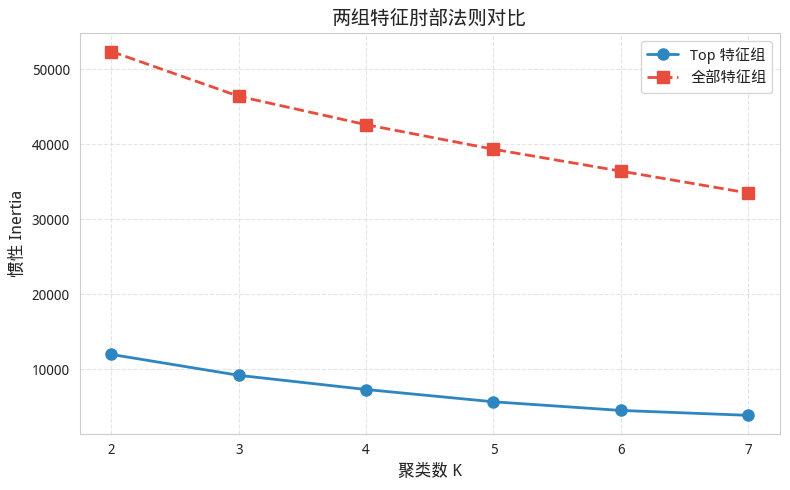

In [92]:
# ===== Cell 12：两组 KMeans 聚类对比 =====
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

# ============================================================
# 0. 准备数据：统一处理缺失值
# ============================================================
all_num_cols = df_aug.select_dtypes(include='number').columns.tolist()
# 排除标签列和后面生成的聚类列
exclude = {'is_wealth', 'cluster_label_top', 'cluster_label_all'}
all_num_cols = [c for c in all_num_cols if c not in exclude]

subset_all = df_aug[all_num_cols].copy()
print("全部数值列缺失值统计：")
print(subset_all.isnull().sum().sort_values(ascending=False).head(10))

# 中位数填充 + 丢弃全空列
subset_all = subset_all.fillna(subset_all.median()).dropna(axis=1)

# ============================================================
# 1. 定义两组特征
# ============================================================
# 第一组：有监督筛选出的 top 特征（根据你前面 LR / RF 的结果调整）
top_features = ['Age', 'total_AUM', 'Mobile_banking', 'time_deposit', 'txn_count_30d']
top_features = [c for c in top_features if c in subset_all.columns]

# 第二组：全部可用数值特征
all_features = subset_all.columns.tolist()

print(f"\nTop 特征组 ({len(top_features)} 个): {top_features}")
print(f"全部特征组 ({len(all_features)} 个): {all_features[:10]}... (省略)")

# ============================================================
# 2. 标准化
# ============================================================
scaler_top = StandardScaler()
X_top = scaler_top.fit_transform(subset_all[top_features])

scaler_all = StandardScaler()
X_all = scaler_all.fit_transform(subset_all[all_features])

# ============================================================
# 3. 肘部法则对比
# ============================================================
K_range = range(2, 8)

inertias_top = []
inertias_all = []
for k in K_range:
    km_t = KMeans(n_clusters=k, random_state=42, n_init=10)
    km_a = KMeans(n_clusters=k, random_state=42, n_init=10)
    inertias_top.append(km_t.fit(X_top).inertia_)
    inertias_all.append(km_a.fit(X_all).inertia_)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(K_range, inertias_top, 'o-', color='#2E86C1', linewidth=2, markersize=8, label='Top 特征组')
ax.plot(K_range, inertias_all, 's--', color='#E74C3C', linewidth=2, markersize=8, label='全部特征组')
ax.set_xlabel('聚类数 K', fontsize=12)
ax.set_ylabel('惯性 Inertia', fontsize=12)
ax.set_title('两组特征肘部法则对比', fontsize=14)
ax.set_xticks(list(K_range))
ax.legend(fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# ============================================================
# 4. 执行聚类（K=4，可根据肘部图调整）
# ============================================================
K_VALUE = 4

km_top = KMeans(n_clusters=K_VALUE, random_state=42, n_init=10)
labels_top = km_top.fit_predict(X_top)

km_all = KMeans(n_clusters=K_VALUE, random_state=42, n_init=10)
labels_all = km_all.fit_predict(X_all)

聚类前缺失值统计：
Age               2000
total_AUM         2000
Mobile_banking       0
time_deposit      2000
txn_count_30d     2000
dtype: int64

实际用于聚类的特征: ['Age', 'total_AUM', 'Mobile_banking', 'time_deposit', 'txn_count_30d']


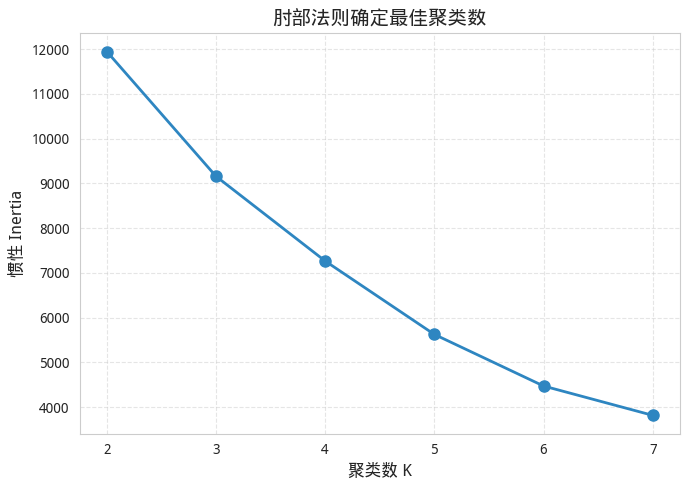

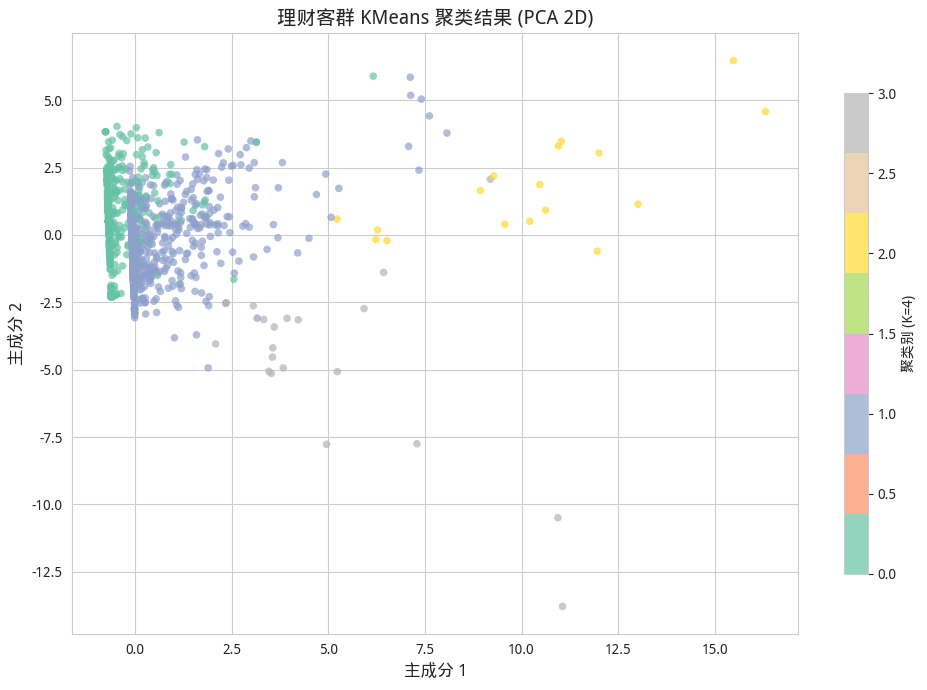


====== 聚类画像 (K=4) ======
           平均年龄      平均总AUM  手机银行开通率       平均定期  近30天交易笔数  理财转化率
第 1 类客群  52.072   64902.549      0.0    534.041     0.223  0.000
第 2 类客群  49.197  109521.486      1.0   1514.265     1.635  0.127
第 3 类客群  49.353  529083.409      1.0  90890.780     6.412  0.353
第 4 类客群  43.150  124929.148      1.0   5297.672    57.350  0.200


In [91]:
# ===== Cell 12：KMeans 聚类分析（含缺失值处理） =====
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. 选择聚类特征
cluster_cols = ['Age', 'total_AUM', 'Mobile_banking', 'time_deposit', 'txn_count_30d']
available = [c for c in cluster_cols if c in df_aug.columns]

# 2. 检查并处理缺失值
subset = df_aug[available].copy()
print("聚类前缺失值统计：")
print(subset.isnull().sum())

# 数值型：用中位数填充（比均值更稳健）
subset = subset.fillna(subset.median())

# 如果还有残留 NaN（比如整列都是空），直接丢弃这些列
subset = subset.dropna(axis=1)

if subset.shape[1] < 3:
    raise ValueError("有效聚类特征不足3个，请检查数据质量")

print(f"\n实际用于聚类的特征: {subset.columns.tolist()}")

# 3. 标准化
Xc = StandardScaler().fit_transform(subset)

# 4. 肘部法则选 K
inertias = []
K_range = range(2, 8)
for k in K_range:
    km_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    inertias.append(km_temp.fit(Xc).inertia_)

plt.figure(figsize=(7, 5))
plt.plot(K_range, inertias, 'o-', color='#2E86C1', linewidth=2, markersize=8)
plt.xlabel('聚类数 K', fontsize=12)
plt.ylabel('惯性 Inertia', fontsize=12)
plt.title('肘部法则确定最佳聚类数', fontsize=14)
plt.xticks(list(K_range))
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 5. 执行聚类
K_VALUE = 4
km = KMeans(n_clusters=K_VALUE, random_state=42, n_init=10)
df_aug['cluster_label'] = km.fit_predict(Xc)

# 6. PCA 2D 可视化
pca = PCA(n_components=2)
X_pca = pca.fit_transform(Xc)

plt.figure(figsize=(10, 7))
sc = plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=df_aug['cluster_label'],
    cmap='Set2', alpha=0.7, s=30, edgecolor='none'
)
plt.colorbar(sc, label=f'聚类别 (K={K_VALUE})', shrink=0.8)
plt.title(f'理财客群 KMeans 聚类结果 (PCA 2D)', fontsize=14)
plt.xlabel('主成分 1', fontsize=12)
plt.ylabel('主成分 2', fontsize=12)
plt.tight_layout()
plt.show()

# 7. 聚类画像
print(f"\n====== 聚类画像 (K={K_VALUE}) ======")
profile_cols = subset.columns.tolist()
if 'is_wealth' in df_aug.columns:
    profile_cols.append('is_wealth')

cluster_profile = df_aug.groupby('cluster_label')[profile_cols].mean().round(3)

chinese_cols = {
    'Age': '平均年龄',
    'total_AUM': '平均总AUM',
    'Mobile_banking': '手机银行开通率',
    'time_deposit': '平均定期',
    'txn_count_30d': '近30天交易笔数',
    'is_wealth': '理财转化率'
}
cluster_profile.index = [f'第 {i+1} 类客群' for i in cluster_profile.index]
print(cluster_profile.rename(columns=lambda c: chinese_cols.get(c, c)))

## Cell 13 · 决策树规则提取（柜面可执行清单）★修复原版 Bug
**作用**：把决策树每条到叶子的路径打印成“规则 → 理财占比”，可直接转成柜面筛查清单。
**改动（这是原版的一个真 bug）**：原版写成了 `tree_ = dt.tree_rules = []`（既没拿到 `dt.tree_`，`rules` 也没初始化），运行必崩。改为 `tree_ = dt.tree_` 并单独 `rules = []`；同时**删掉了原版重复且同样错误的 Cell 13**。
**为什么**：`dt.tree_` 才是 sklearn 决策树存放结构（children_left/feature/threshold/value）的对象。
**补充**：折叠了，输出规则适用的样本点太少了，不太具备代表意义，后续数据集规模如果有望扩大，还是未来可期的，故未做刪除处理。

In [96]:
# ===== Cell 13（增强版）：决策树规则提取 + 中文翻译 =====

# 1. 字段中文名映射
COL_ZH = {
    'Mobile_banking':   '手机银行',
    'total_AUM':        '总AUM',
    'average_AUM':      '平均AUM',
    'time_deposit':     '定期存款',
    'average_time_deposit': '平均定期存款',
    'txn_count_30d':    '近30天交易笔数',
    'Age':              '年龄',
    'Gender':           '性别',
    'occ_freq':         '职业频次',
    'is_wealth':        '是否理财客户',
}

# 2. 取值含义映射（按你数据的实际编码调整）
VALUE_ZH = {
    'Mobile_banking':   {0.0: '未开通', 1.0: '已开通'},
    'Gender':           {2.0: '女', 1.0: '男'},
}

def describe_feat(name, op, val):
    """把 'Mobile_banking <= 0.50' 翻译成人类可读的中文"""
    zh = COL_ZH.get(name, name)
    # 有明确取值含义的，直接翻译
    if name in VALUE_ZH:
        if op == '<=' and val < 1.0:
            return f"{zh} = {VALUE_ZH[name].get(0.0, '未开通')}"
        if op == '>' and val < 1.0:
            return f"{zh} = {VALUE_ZH[name].get(1.0, '已开通')}"
    # 通用翻译
    if op == '<=':
        return f"{zh} ≤ {val:.2f}"
    if op == '>':
        return f"{zh} > {val:.2f}"
    return f"{zh} {op} {val:.2f}"


# 3. 对齐特征名
if hasattr(dt, 'feature_names_in_'):
    tree_feat_names = list(dt.feature_names_in_)
else:
    tree_feat_names = feature_cols

print(f"决策树使用特征数: {len(tree_feat_names)}\n")

# 4. 递归提取规则（限制深度）
tree_ = dt.tree_
rules = []

def traverse(node, conditions, depth=0, max_depth=4):
    if tree_.children_left[node] == -1 or depth >= max_depth:
        n_total = tree_.value[node][0].sum()
        n_pos = tree_.value[node][0][1]
        ratio = n_pos / n_total if n_total > 0 else 0
        rules.append((conditions.copy(), n_total, n_pos, ratio, depth))
        return

    feat_idx = tree_.feature[node]
    thr = tree_.threshold[node]
    feat_name = tree_feat_names[feat_idx] if feat_idx < len(tree_feat_names) else f'feat_{feat_idx}'

    conditions.append((feat_name, '<=', thr))
    traverse(tree_.children_left[node], conditions, depth + 1, max_depth)
    conditions.pop()

    conditions.append((feat_name, '>', thr))
    traverse(tree_.children_right[node], conditions, depth + 1, max_depth)
    conditions.pop()

traverse(0, [])

# 5. 按理财占比降序，输出可读规则
rules.sort(key=lambda x: x[3], reverse=True)

print(f'共提取 {len(rules)} 条规则（深度≤4）\n')
print('=' * 80)
print('决策树主要分裂路径（按理财客户占比降序）')
print('=' * 80)

for i, (cond, n_total, n_pos, ratio, depth) in enumerate(rules):
    # 翻译条件
    zh_parts = [describe_feat(name, op, val) for name, op, val in cond]
    path = ' 且 '.join(zh_parts) if zh_parts else '(根节点)'

    # 样本量太少加提示
    tag = ''
    if n_total <= 5:
        tag = '  ⚠️ 样本极少'

    print(f'规则 {i+1:02d} | 样本={n_total:5.0f}, 理财={n_pos:5.0f}, '
          f'占比={ratio:6.2%}{tag}')
    print(f'         {path}\n')

决策树使用特征数: 12

共提取 9 条规则（深度≤4）

决策树主要分裂路径（按理财客户占比降序）
规则 01 | 样本=    1, 理财=    1, 占比=96.32%  ⚠️ 样本极少
         手机银行 = 已开通 且 总AUM > 24415.37 且 平均定期存款 > 0.75 且 平均AUM ≤ 22630.58

规则 02 | 样本=    1, 理财=    1, 占比=96.07%  ⚠️ 样本极少
         手机银行 = 已开通 且 总AUM > 24415.37 且 平均定期存款 ≤ 0.75 且 总AUM > 666583.12

规则 03 | 样本=    1, 理财=    1, 占比=79.57%  ⚠️ 样本极少
         手机银行 = 已开通 且 总AUM > 24415.37 且 平均定期存款 > 0.75 且 平均AUM > 22630.58

规则 04 | 样本=    1, 理财=    1, 占比=72.97%  ⚠️ 样本极少
         手机银行 = 已开通 且 总AUM ≤ 24415.37 且 性别 > 1.50 且 定期存款 ≤ 0.93

规则 05 | 样本=    1, 理财=    1, 占比=66.97%  ⚠️ 样本极少
         手机银行 = 已开通 且 总AUM ≤ 24415.37 且 性别 ≤ 1.50 且 职业频次 ≤ 4.50

规则 06 | 样本=    1, 理财=    0, 占比=41.41%  ⚠️ 样本极少
         手机银行 = 已开通 且 总AUM ≤ 24415.37 且 性别 > 1.50 且 定期存款 > 0.93

规则 07 | 样本=    1, 理财=    0, 占比=39.38%  ⚠️ 样本极少
         手机银行 = 已开通 且 总AUM > 24415.37 且 平均定期存款 ≤ 0.75 且 总AUM ≤ 666583.12

规则 08 | 样本=    1, 理财=    0, 占比=19.69%  ⚠️ 样本极少
         手机银行 = 已开通 且 总AUM ≤ 24415.37 且 性别 ≤ 1.50 且 职业频次 > 4.50

规则 09 | 样本=    1

In [97]:
# ===== Cell 13：决策树规则提取（已修复）=====
tree_ = dt.tree_          # 原版误写成 dt.tree_rules，导致 AttributeError
rules = []                # 原版 rules 未初始化

def traverse(node, conditions):
    if tree_.children_left[node] == -1:                 # 叶子
        rules.append((conditions.copy(), tree_.value[node][0])); return
    feat = feature_cols[tree_.feature[node]]; thr = tree_.threshold[node]
    conditions.append(f'{feat} <= {thr:.2f}')
    traverse(tree_.children_left[node], conditions); conditions.pop()
    conditions.append(f'{feat} > {thr:.2f}')
    traverse(tree_.children_right[node], conditions); conditions.pop()

traverse(0, [])
print('主要分裂路径：')
for cond, val in rules:
    ratio = val[1] / (val[0] + val[1]) if (val[0] + val[1]) > 0 else 0
    print('  ', ' 且 '.join(cond), f' →  理财客户占比约 {ratio:.2%}')

主要分裂路径：
   Mobile_banking <= 0.50  →  理财客户占比约 0.00%
   Mobile_banking > 0.50 且 occ_其他生产制造及有关人员 <= 24415.37 且 Gender <= 1.50 且 occ_专业技术人员 <= 4.50  →  理财客户占比约 66.97%
   Mobile_banking > 0.50 且 occ_其他生产制造及有关人员 <= 24415.37 且 Gender <= 1.50 且 occ_专业技术人员 > 4.50  →  理财客户占比约 19.69%
   Mobile_banking > 0.50 且 occ_其他生产制造及有关人员 <= 24415.37 且 Gender > 1.50 且 occ_社会生产服务和生活服务人员 <= 0.93  →  理财客户占比约 72.97%
   Mobile_banking > 0.50 且 occ_其他生产制造及有关人员 <= 24415.37 且 Gender > 1.50 且 occ_社会生产服务和生活服务人员 > 0.93  →  理财客户占比约 41.41%
   Mobile_banking > 0.50 且 occ_其他生产制造及有关人员 > 24415.37 且 occ_非从业人员 <= 0.75 且 occ_其他生产制造及有关人员 <= 666583.12  →  理财客户占比约 39.38%
   Mobile_banking > 0.50 且 occ_其他生产制造及有关人员 > 24415.37 且 occ_非从业人员 <= 0.75 且 occ_其他生产制造及有关人员 > 666583.12  →  理财客户占比约 96.07%
   Mobile_banking > 0.50 且 occ_其他生产制造及有关人员 > 24415.37 且 occ_非从业人员 > 0.75 且 occ_其他社会生产和生活服务人员 <= 22630.58  →  理财客户占比约 96.32%
   Mobile_banking > 0.50 且 occ_其他生产制造及有关人员 > 24415.37 且 occ_非从业人员 > 0.75 且 occ_其他社会生产和生活服务人员 > 22630.58  →  理财客户占比约 79.

# Cell 14 · 保存